# Módulo: MODELOS DE INTELIGENCIA ARTIFICIAL
## Ejercicio práctico 1.
## Sistema Basado en Reglas   
### Análisis de la calidad del aire

De forma similar a lo realizado en el notebook SBR_IRIS, construye un sistema de clasificación de la calidad del aire (AirQuality - AQI) en función de la cantidad de Ozono detectado en el mismo.   
Los valores del nivel de AQI se muestran en la siguiente tabla:  


| NIVEL AQI | RANGO-DESCRIPCIÓN|
|:---------:|:----------------:|
|   BUENO   |     0 - 50       |
| MODERADO  |    51 - 100      |
|CONTAMINADO|   101 - 150      |
|  INSANO   |   151 - 200      |
| PELIGROSO |       > 200      |

Se pide intentar establecer la clasificación según la tabla anterior en base a alguna de las características que conforman el dataset (Valor de O2, Valor de CO, Valor de NO2, Valor de PM2.5, Longitud y Latitud).   
Como los datos son numéricos y no faltan valores, no se requiere ningún procesamiento previo.   

Nuestro objetivo es predecir el AQI, por lo que esta tarea sería de clasificación o de regresión, pero en este caso vamos a tratar de establecer un SBR basado en una de las variables independientes citadas.

<u>Nota sobre la característica ***PM2.5***</u> :   
Este valor se corresponde con la concentración del material particulado (*PM - Particulate Matter*) de la fracción de tamaño PM2,5 (2.5 micrometros), el cúal se encuentra íntimamente asociado a problemas de salud dado que entre sus efectos aparecen impactos claros sobre las enfermedades cardiacas y pulmonares.   

Importamos librerías necesarias

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultamos los warnings de las librerías
import warnings
warnings.filterwarnings("ignore")
# ------------------------------------------------

Cargamos dataset *airquality.csv*

In [2]:
# Cargamos el dataset
data = pd.read_csv('datasets/airquality.csv')

Mostramos los primeros registros

In [3]:
data.head()

,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,lat,lng
0,51,1,36,0,51,44.7444,44.2031
1,41,1,5,1,41,-5.2900,-44.4900
2,41,1,5,1,41,-11.2958,-41.9869
3,66,1,39,2,66,37.1667,15.1833
4,34,1,34,0,20,53.0167,20.8833


Asignación (mapeo) del nivel de calidad según los valores del mismo

In [4]:
def clasificacion_AQI_VALUE(value):
    if value <50:
        return "BUENO"
    elif value <100:
        return "MODERADO"
    elif value <150:
        return "CONTAMINADO"
    elif value<200:
        return "INSANO"
    else:
        return "PELIGROSO"


def asignar_nodo(row):
    return clasificacion_AQI_VALUE(row['AQI Value'])

data['nodo']=data.apply(asignar_nodo,axis=1)

data.head()

,AQI Value,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value,lat,lng,nodo
0,51,1,36,0,51,44.7444,44.2031,MODERADO
1,41,1,5,1,41,-5.2900,-44.4900,BUENO
2,41,1,5,1,41,-11.2958,-41.9869,BUENO
3,66,1,39,2,66,37.1667,15.1833,MODERADO
4,34,1,34,0,20,53.0167,20.8833,BUENO


Análisis breve del dataset (EDA)

16695


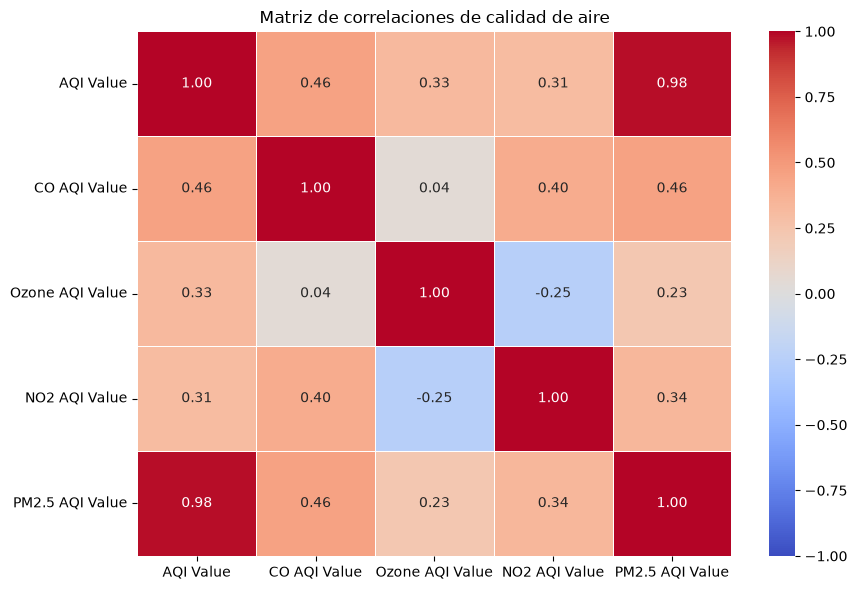

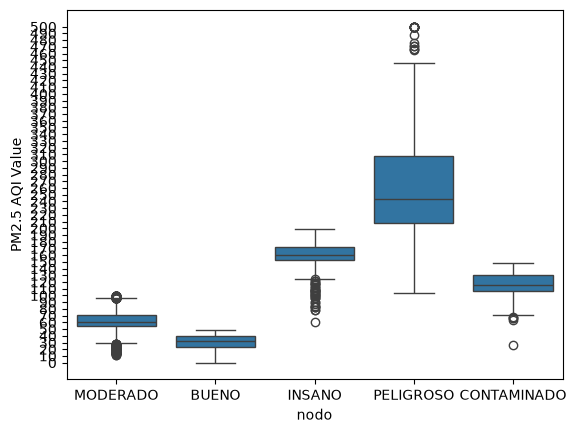

In [41]:
print(data.shape[0])
data.describe()
# ============================================
# Matriz de correlaciones
# ============================================
 
columnas = [
    "AQI Value",
    "CO AQI Value",
    "Ozone AQI Value",
    "NO2 AQI Value",
    "PM2.5 AQI Value",
]
 
correlaciones = data[columnas].corr()
 
plt.figure(figsize=(9, 6))
 
sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)
 
plt.title("Matriz de correlaciones de calidad de aire")
plt.tight_layout()
plt.show()

plt.show()
fig,ax=plt.subplots()
sns.boxplot(
    data=data,
    x='nodo',
    y='PM2.5 AQI Value'
)
ax.set_yticks(range(0,501,10))


plt.show()


Definición de reglas

In [43]:
def clasificacion_basado_en_reglas(pmi25_value):
    if pmi25_value<50:
        return "BUENO"
    elif pmi25_value <100:
        return "MODERADO"
    elif pmi25_value<150:
        return "CONTAMINADO"
    elif pmi25_value<200:
        return "INSANO"
    else:
        return "PELIGROSO"

def asignar_reglas(row):
    return clasificacion_basado_en_reglas(row['PM2.5 AQI Value'])

Aplicación de reglas

In [44]:
data['PM_Nodo']=data.apply(asignar_reglas,axis=1)

Visualización gráfica

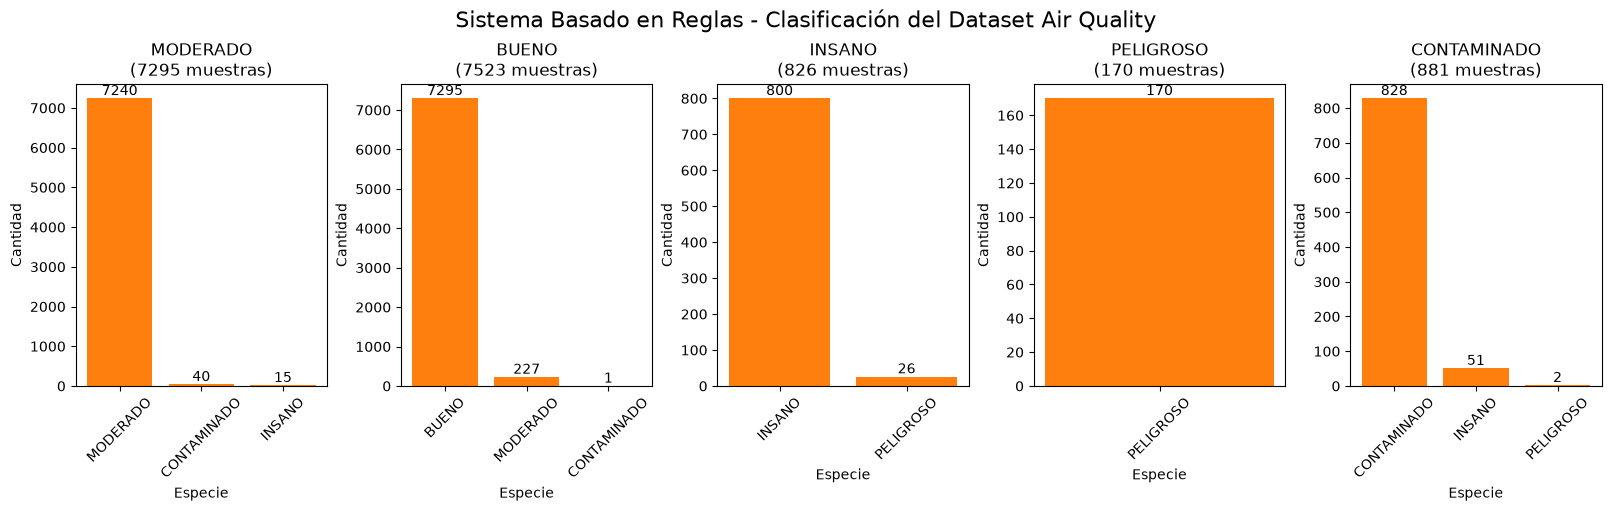

In [48]:
nodos_finales=data['PM_Nodo'].unique()
fig, axes = plt.subplots(1, len(nodos_finales), figsize=(16, 5), constrained_layout=True)

for ax, nodo in zip(axes, nodos_finales):
    nodo_data = data[data['PM_Nodo'] == nodo]
    quality = nodo_data['nodo'].value_counts()
    # Crear las barras
    bars = ax.bar(quality.index, quality.values)
    
    # Añadir las cantidades encima de las barras
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,  # Posición horizontal (centro de la barra)
            height,  # Posición vertical (altura de la barra)
            str(height),  # Texto a mostrar (la cantidad)
            ha='center', va='bottom', fontsize=10  # Alineación y tamaño de fuente
        )
    
    # Configurar títulos y etiquetas
    ax.bar(quality.index, quality.values)
    ax.set_title(f"{nodo}\n({len(nodo_data)} muestras)")
    ax.set_xlabel("Especie")
    ax.set_ylabel("Cantidad")
    ax.set_xticklabels(quality.index, rotation=45)

plt.suptitle("Sistema Basado en Reglas - Clasificación del Dataset Air Quality", fontsize=16)
plt.show()